<a href="https://colab.research.google.com/github/reezyhudson865/AI_Projects/blob/main/RHudson_ClassifyingEmotion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI 301 - Challenge Lab: Classifying Emotion

**Course:** AI 301 - Natural Language Processing and Conversational AI
**Student:** Reezy Hudson   

The following notebook follows a lab completed in an undergrad Applied AI class at UT-Knoxville in the Fall 2027 semester. It follows classifying emotion using things like flan. The lab follows a model outlined by the professor. All rights reserved.

In [ ]:
!pip install -q transformers datasets sentence-transformers

In [ ]:
import warnings
warnings.filterwarnings("ignore")

from transformers import logging as hf_logging
hf_logging.set_verbosity_error()

import numpy as np
import torch
from collections import Counter
from datasets import load_dataset
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

try:
    # TODO: load the dataset
    # hint: the repository id is on the card. It has two configurations; use the one that
    # comes with train, validation and test splits
    data = load_dataset("dair-ai/emotion", "split")

    # TODO: the training split and the test split
    train = data['train']
    test = data['test']

    # given: the label names, in the dataset's own order, which is what every label id refers to
    emotions = data["train"].features["label"].names
    print("labels:", emotions)

    # TODO: 0 when a GPU is attached, -1 otherwise
    # hint: the same line every guided lab in this module used
    device = 0 if torch.cuda.is_available() else -1
    print("running on", "GPU" if device == 0 else "CPU")

    print()
    print("training split:", len(train), "rows")
    print("test split    :", len(test), "rows")
    print()

    # TODO: count how many training rows have each label id
    # hint: the class you imported above counts the values in a list
    counts = Counter(train['label'])
    for label_id in range(len(emotions)):
        print(emotions[label_id], counts[label_id])

    print()
    print(test[0])
except NameError:
    print("Fill in the blanks above, then run this cell again.")

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

labels: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
running on GPU

training split: 16000 rows
test split    : 2000 rows

sadness 4666
joy 5362
love 1304
anger 2159
fear 1937
surprise 572

{'text': 'im feeling rather rotten so im not very ambitious right now', 'label': 0}


Unlike the Rotten Tomatoes reviews in the guided labs, which were split evenly between positive and
negative, this dataset is imbalanced. The chart below shows by how much.

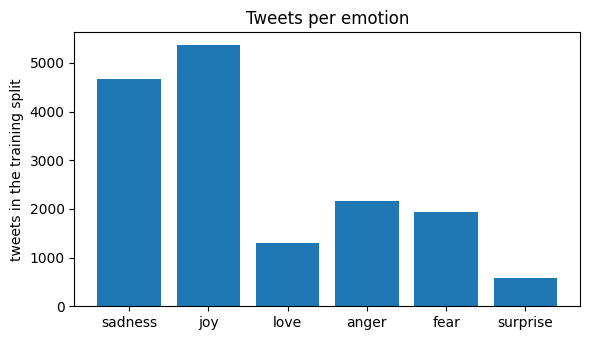

In [ ]:
try:
    heights = []
    for label_id in range(len(emotions)):
        heights.append(counts[label_id])

    figure, axes = plt.subplots(figsize=(6, 3.5))
    axes.bar(emotions, heights)
    axes.set_ylabel("tweets in the training split")
    axes.set_title("Tweets per emotion")
    plt.tight_layout()
    plt.show()
except NameError:
    print("Fill in the cell above first.")

The evaluation helper is given too. Every exercise ends by calling it, so every run is scored the
same way.

In [ ]:
def evaluate(y_true, y_pred, title=""):
    # print the per class scores and draw the confusion matrix as percentages
    # labels= keeps all six rows even when a route never predicts one of them
    print(classification_report(
        y_true, y_pred, labels=range(len(emotions)), target_names=emotions, digits=3, zero_division=0
    ))

    rates = confusion_matrix(y_true, y_pred, labels=range(len(emotions)), normalize="true")

    figure, axes = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(rates, display_labels=emotions).plot(
        ax=axes, cmap="Blues", colorbar=False, values_format=".0%", xticks_rotation=45
    )
    axes.set_title(title if title else "Percent of each true class")
    plt.tight_layout()
    plt.show()

In [ ]:
from transformers import pipeline
from tqdm import tqdm

try:
    # TODO: the model you chose from the table above
    model_name = "j-hartmann/emotion-english-distilroberta-base"

    # TODO: load it as a text classification pipeline on the device from Exercise 1
    # hint: Guided Lab Part 1, Part 2. Leave out top_k=None and the pipeline returns only the
    # top label for each tweet, which is all you need here
    classifier = pipeline('text-classification', model=model_name, device=device)

    # given: every label this model can return
    print(classifier.model.config.id2label)

    # TODO: map every label the model can return to one of our six labels, one line per label,
    # lowercased. The first line is done for you.
    # hint: emotions.index(name) gives the id. The labels with no match still need an entry;
    # decide which of our six each one goes to.
    label_map = {
        "anger": emotions.index("anger"),
        "fear": emotions.index("fear"),
        "joy": emotions.index("joy"),
        "sadness": emotions.index("sadness"),
        "surprise": emotions.index("surprise"),
        "neutral": emotions.index("joy"),
        "disgust": emotions.index("anger"),

    }

    task_pred = []
    for row in tqdm(test):
        # given: the classifier returns a list holding one dictionary, for example
        # [{'label': 'joy', 'score': 0.97}], so [0] takes that dictionary
        output = classifier(row["text"])[0]

        # TODO: the label name from that dictionary, lowercased
        # hint: the dictionary key is in the example above
        name = output["label"].lower()

        task_pred.append(label_map[name])

    evaluate(test["label"], task_pred, title="task-specific model")
except NameError:
    print("Fill in the blanks above, then run this cell again.")

# Expected output (your numbers will differ):
#
# {0: 'anger', 1: 'disgust', 2: 'fear', ...}
# 100%|██████████| 2000/2000 [0x:xx<00:00]
#
#               precision    recall  f1-score   support
#
#      sadness      0.xxx     0.xxx     0.xxx       xxx
#          joy      0.xxx     0.xxx     0.xxx       xxx
#         love      0.xxx     0.xxx     0.xxx       xxx
#        anger      0.xxx     0.xxx     0.xxx       xxx
#         fear      0.xxx     0.xxx     0.xxx       xxx
#     surprise      0.xxx     0.xxx     0.xxx       xxx
#
#     accuracy                          0.xxx      2000
#    macro avg      0.xxx     0.xxx     0.xxx      2000
# weighted avg      0.xxx     0.xxx     0.xxx      2000
#
# [confusion matrix]

config.json:   0%|          | 0.00/1.00k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  329MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/294 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

... (3 outputs left out)

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

{0: 'anger', 1: 'disgust', 2: 'fear', 3: 'joy', 4: 'neutral', 5: 'sadness', 6: 'surprise'}




  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 1/2000 [00:02<1:06:49,  2.01s/it]

  0%|          | 6/2000 [00:02<08:48,  3.77it/s]  

  1%|          | 13/2000 [00:02<03:29,  9.48it/s]

  1%|          | 22/2000 [00:02<01:49, 18.14it/s]

  2%|▏         | 31/2000 [00:02<01:11, 27.44it/s]

  2%|▏         | 40/2000 [00:02<00:52, 37.08it/s]

  2%|▏         | 48/2000 [00:02<00:44, 43.60it/s]

  3%|▎         | 56/2000 [00:02<00:40, 48.42it/s]

  3%|▎         | 63/2000 [00:02<00:37, 52.08it/s]

  4%|▎         | 72/2000 [00:02<00:32, 60.03it/s]

  4%|▍         | 82/2000 [00:03<00:27, 68.98it/s]

  5%|▍         | 91/2000 [00:03<00:25, 74.27it/s]

  5%|▌         | 101/2000 [00:03<00:23, 79.35it/s]

  6%|▌         | 110/2000 [00:03<00:23, 79.79it/s]

  6%|▌         | 120/2000 [00:03<00:22, 83.19it/s]

  6%|▋         | 129/2000 [00:03<00:24, 77.55it/s]

  7%|▋         | 138/2000 [00:03<00:24, 76.93it/s]

  7%|▋         | 147/2000 [00:03<00:23, 78.50it/s]

  8%|▊         | 156/2000 [00:

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/500 [00:00<?, ?it/s]

Batches:   0%|          | 0/63 [00:00<?, ?it/s]

training vectors: (16000, 768)
              precision    recall  f1-score   support

     sadness      0.695     0.766     0.729       581
         joy      0.701     0.806     0.750       695
        love      0.510     0.321     0.394       159
       anger      0.643     0.531     0.582       275
        fear      0.649     0.612     0.630       224
    surprise      0.565     0.197     0.292        66

    accuracy                          0.676      2000
   macro avg      0.627     0.539     0.563      2000
weighted avg      0.666     0.676     0.664      2000



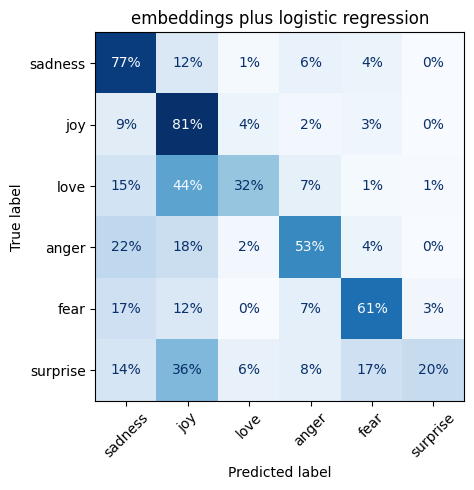

In [ ]:
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression

try:
    # TODO: load the embedding model sentence-transformers/all-mpnet-base-v2
    # hint: Guided Lab Part 2, Part 1
    embedder = SentenceTransformer("sentence-transformers/all-mpnet-base-v2")

    # TODO: encode the text of the training split and of the test split
    # hint: .encode takes a list of strings; show_progress_bar=True draws the bar
    train_vectors = embedder.encode(train['text'], show_progress_bar=True)
    test_vectors = embedder.encode(test['text'], show_progress_bar=True)
    print("training vectors:", train_vectors.shape)

    # TODO: a logistic regression with random_state=42 and max_iter=1000
    # hint: Guided Lab Part 2, Part 2
    model = LogisticRegression(random_state=42, max_iter=1000)

    # TODO: train it on the training vectors and the training labels
    model.fit(train_vectors, train['label'])

    embedding_pred = model.predict(test_vectors)
    evaluate(test["label"], embedding_pred, title="embeddings plus logistic regression")
except NameError:
    print("Fill in the blanks above, then run this cell again.")

# Expected output (your numbers will differ):
#
# Batches: 100%|██████████| 500/500 [0x:xx<00:00]
# Batches: 100%|██████████| 63/63 [00:xx<00:00]
# training vectors: (16000, 768)
#
# [classification report and confusion matrix]

              precision    recall  f1-score   support

     sadness      0.776     0.639     0.701       581
         joy      0.807     0.584     0.678       695
        love      0.322     0.572     0.412       159
       anger      0.556     0.633     0.592       275
        fear      0.557     0.679     0.612       224
    surprise      0.260     0.591     0.361        66

    accuracy                          0.617      2000
   macro avg      0.546     0.616     0.559      2000
weighted avg      0.679     0.617     0.634      2000



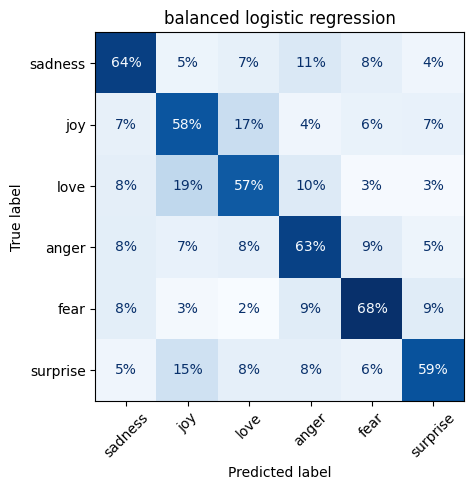

In [ ]:
try:
    # TODO: the same logistic regression with class_weight="balanced"
    # hint: the only change from the cell above is one extra argument
    balanced = LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced')
    balanced.fit(train_vectors, train["label"])

    balanced_pred = balanced.predict(test_vectors)
    evaluate(test["label"], balanced_pred, title="balanced logistic regression")
except NameError:
    print("Fill in the blanks above, then run this cell again.")

# Expected output (your numbers will differ):
#
# [classification report and confusion matrix]

              precision    recall  f1-score   support

     sadness      0.614     0.398     0.483       581
         joy      0.605     0.584     0.594       695
        love      0.219     0.289     0.249       159
       anger      0.520     0.378     0.438       275
        fear      0.367     0.585     0.451       224
    surprise      0.129     0.364     0.190        66

    accuracy                          0.471      2000
   macro avg      0.409     0.433     0.401      2000
weighted avg      0.523     0.471     0.484      2000



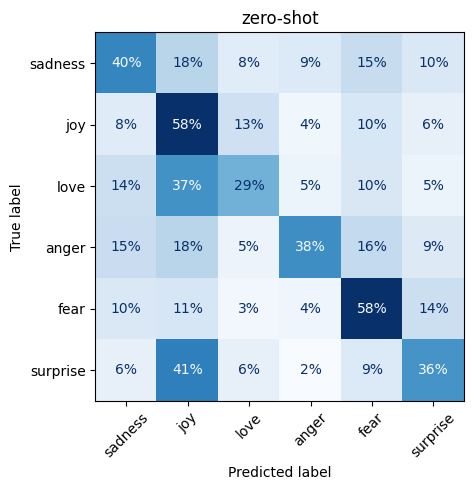

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

try:
    # TODO: six descriptions, one per emotion, in the same order as emotions
    # hint: Guided Lab Part 2, Part 3 used "A negative review" and "A positive review"
    descriptions = ['A message expressing sadness, unhappiness, or grief',
                    'A message expressing happiness, excitement, or pleasure',
                    'A message expressing affection, love, or caring for someone',
                    'A message expressing anger, frustration, or irritation',
                    'A message expressing fear, worry, or anxiety',
                    'A message expressing surprise, shock, or something unexpected',
    ]

    if len(descriptions) != len(emotions):
        print("Write one description per emotion, then run this cell again.")
    else:
        # TODO: encode the descriptions with the embedder from Exercise 3
        description_vectors = embedder.encode(descriptions)

        # TODO: the similarity of every test vector to each description
        similarities = cosine_similarity(test_vectors, description_vectors)

        # TODO: the position of the closest description for each tweet
        # hint: Guided Lab Part 2, Part 3 explained which axis gives one value per row
        zero_shot_pred = np.argmax(similarities, axis=1)
        evaluate(test["label"], zero_shot_pred, title="zero-shot")
except NameError:
    print("Fill in the blanks above, then run this cell again.")

# Expected output (your numbers will differ):
#
# [classification report and confusion matrix]

one average vector per class: (6, 768)
              precision    recall  f1-score   support

     sadness      0.650     0.523     0.580       581
         joy      0.730     0.514     0.603       695
        love      0.269     0.491     0.347       159
       anger      0.461     0.498     0.479       275
        fear      0.458     0.567     0.507       224
    surprise      0.190     0.515     0.278        66

    accuracy                          0.518      2000
   macro avg      0.460     0.518     0.466      2000
weighted avg      0.585     0.518     0.537      2000



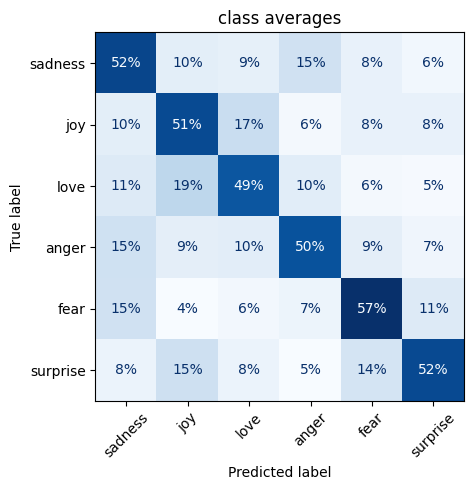

In [ ]:
try:
    train_labels = np.array(train["label"])

    class_averages = []
    for label_id in range(len(emotions)):
        # given: the training vectors whose label is label_id
        class_vectors = train_vectors[train_labels == label_id]

        # TODO: their average, one vector of 768 numbers
        # hint: Guided Lab Part 2, Part 4 used np.mean with axis=0
        class_averages.append(np.mean(class_vectors, axis=0))

    class_averages = np.array(class_averages)
    print("one average vector per class:", class_averages.shape)

    # TODO: the similarity of every test vector to each class average
    average_similarities = cosine_similarity(test_vectors, class_averages)

    # TODO: the position of the closest average for each tweet
    average_pred = np.argmax(average_similarities, axis=1)
    evaluate(test["label"], average_pred, title="class averages")
except NameError:
    print("Fill in the blanks above, then run this cell again.")

# Expected output (your numbers will differ):
#
# one average vector per class: (6, 768)
# [classification report and confusion matrix]

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

100%|██████████| 63/63 [00:10<00:00,  6.30it/s]


[('sadness', 705), ('joy', 463), ('love', 322), ('surprise', 202), ('anger', 198), ('fear', 110)]
answers outside the six emotions: 0
              precision    recall  f1-score   support

     sadness      0.576     0.699     0.631       581
         joy      0.782     0.521     0.625       695
        love      0.258     0.522     0.345       159
       anger      0.535     0.385     0.448       275
        fear      0.700     0.344     0.461       224
    surprise      0.193     0.591     0.291        66

    accuracy                          0.536      2000
   macro avg      0.507     0.510     0.467      2000
weighted avg      0.618     0.536     0.551      2000



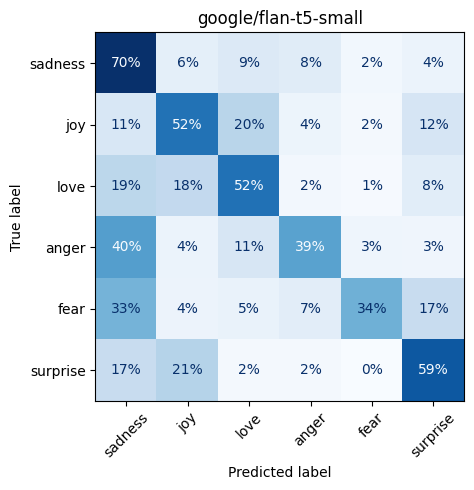

config.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

100%|██████████| 63/63 [00:50<00:00,  1.25it/s]


[('sadness', 423), ('joy', 406), ('anger', 386), ('love', 368), ('fear', 270), ('surprise', 147)]
answers outside the six emotions: 0
              precision    recall  f1-score   support

     sadness      0.804     0.585     0.677       581
         joy      0.852     0.498     0.629       695
        love      0.329     0.761     0.459       159
       anger      0.534     0.749     0.623       275
        fear      0.556     0.670     0.607       224
    surprise      0.395     0.879     0.545        66

    accuracy                          0.611      2000
   macro avg      0.578     0.690     0.590      2000
weighted avg      0.704     0.611     0.623      2000



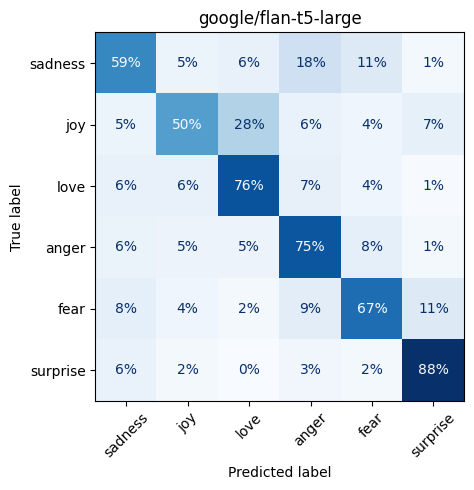

In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from tqdm import tqdm


def classify_with_flan(flan_name):
    # TODO: load the tokenizer and the model for flan_name
    # hint: Guided Lab Part 3, Part 1
    flan_tokenizer = AutoTokenizer.from_pretrained(flan_name)
    flan_model = AutoModelForSeq2SeqLM.from_pretrained(flan_name)
    if device == 0:
        flan_model = flan_model.to("cuda")

    # given: the same steps as generate_answers in Guided Lab Part 3, over the test split.
    # batch_size is how many tweets go through the model in one call; larger is faster
    # but needs more GPU memory
    batch_size = 32
    generated = []
    for start in tqdm(range(0, len(test), batch_size)):
        batch = test["text"][start:start + batch_size]
        prompts = []
        for text in batch:
            prompts.append(instruction + text)
        inputs = flan_tokenizer(prompts, return_tensors="pt", padding=True, truncation=True)
        if device == 0:
            inputs = inputs.to("cuda")
        outputs = flan_model.generate(**inputs, max_new_tokens=5)
        for row in outputs:
            generated.append(flan_tokenizer.decode(row, skip_special_tokens=True))

    # TODO: print every distinct answer with its count
    # hint: Guided Lab Part 3, Part 2
    print(Counter(generated).most_common())

    predictions = []
    outside = 0
    for answer in generated:
        word = answer.strip().lower()
        # TODO: when word is one of our six emotions, append its id
        # hint: "word in emotions" checks it, emotions.index(word) gives the id
        if word in emotions:
            predictions.append(emotions.index(word))
        else:
            # given: anything else is counted, and sent to joy, the largest class
            outside += 1
            predictions.append(emotions.index("joy"))

    print("answers outside the six emotions:", outside)
    evaluate(test["label"], predictions, title=flan_name)
    return predictions


try:
    # TODO: an instruction that names the six emotions and asks for one word
    # hint: Guided Lab Part 3, Part 1 asked "Is the following sentence positive or negative? "
    instruction = "Classify the following sentence as sadness, joy, love, anger, fear, or surprise. Respond with one word: "

    # TODO: run the function twice, once for each model, and keep both sets of predictions.
    # The names are google/flan-t5-small and google/flan-t5-large. Small runs in about a
    # minute, large takes several minutes on a T4
    flan_small_pred = classify_with_flan("google/flan-t5-small")
    flan_large_pred = classify_with_flan("google/flan-t5-large")
except NameError:
    print("Fill in the blanks above, then run this cell again.")

# Expected output (your numbers and your model's answers will differ), once for each model:
#
# 100%|██████████| 63/63 [0x:xx<00:00]
# [('joy', xxx), ('sadness', xxx), ('love', xx), ('anger', xx), ('fear', xx), ('surprise', x), ('...', x)]
# answers outside the six emotions: xx
#
# [classification report and confusion matrix]

In [ ]:
from sklearn.metrics import f1_score

try:
    runs = {
        "task-specific": task_pred,
        "embeddings plus logistic regression": embedding_pred,
        "balanced logistic regression": balanced_pred,
        "zero-shot": zero_shot_pred,
        "class averages": average_pred,
        "flan-t5 small": flan_small_pred,
        "flan-t5 large": flan_large_pred,
    }
except NameError as missing:
    runs = {}
    print("Run Exercises 2 to 5 first:", missing)

for name in runs:
    macro = f1_score(test["label"], runs[name], average="macro", zero_division=0)
    weighted = f1_score(test["label"], runs[name], average="weighted", zero_division=0)
    print(name, "macro", round(macro, 3), "weighted", round(weighted, 3))

# TODO: the predictions of your best run that has not seen this dataset, for example balanced_pred
best_pred = flan_large_pred

if best_pred is None:
    print()
    print("Set best_pred above, then run this cell again to see five mistakes.")
else:
    print()
    shown = 0
    for i in range(len(test)):
        if best_pred[i] != test[i]["label"] and shown < 5:
            print("true:", emotions[test[i]["label"]], "predicted:", emotions[int(best_pred[i])], test[i]["text"])
            shown += 1

# Expected output (your numbers will differ):
#
# task-specific macro 0.xxx weighted 0.xxx
# embeddings plus logistic regression macro 0.xxx weighted 0.xxx
# balanced logistic regression macro 0.xxx weighted 0.xxx
# zero-shot macro 0.xxx weighted 0.xxx
# class averages macro 0.xxx weighted 0.xxx
# flan-t5 small macro 0.xxx weighted 0.xxx
# flan-t5 large macro 0.xxx weighted 0.xxx
#
# true: <emotion> predicted: <emotion> <the tweet>
# (five lines)

task-specific macro 0.699 weighted 0.807
embeddings plus logistic regression macro 0.563 weighted 0.664
balanced logistic regression macro 0.559 weighted 0.634
zero-shot macro 0.401 weighted 0.484
class averages macro 0.466 weighted 0.537
flan-t5 small macro 0.467 weighted 0.551
flan-t5 large macro 0.59 weighted 0.623

true: sadness predicted: love i never make her separate from me because i don t ever want her to feel like i m ashamed with her
true: sadness predicted: anger i was feeling a little vain when i did this one
true: joy predicted: love i explain why i clung to a relationship with a boy who was in many ways immature and uncommitted despite the excitement i should have been feeling for getting accepted into the masters program at the university of virginia
true: joy predicted: surprise i like to have the same breathless feeling as a reader eager to see what will happen next
true: fear predicted: anger i don t feel particularly agitated


## References

- [dair-ai/emotion](https://huggingface.co/datasets/dair-ai/emotion)
- [j-hartmann/emotion-english-distilroberta-base](https://huggingface.co/j-hartmann/emotion-english-distilroberta-base)
- [SamLowe/roberta-base-go_emotions](https://huggingface.co/SamLowe/roberta-base-go_emotions)
- [sentence-transformers/all-mpnet-base-v2](https://huggingface.co/sentence-transformers/all-mpnet-base-v2)
- [google/flan-t5-small](https://huggingface.co/google/flan-t5-small)
- [google/flan-t5-large](https://huggingface.co/google/flan-t5-large)
- [scikit-learn, LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)
- [scikit-learn, metrics and scoring](https://scikit-learn.org/stable/modules/model_evaluation.html)
- Alammar and Grootendorst, *Hands-On Large Language Models*, Chapter 4